# Stress-testing benchmark portfolios

Held-out volatility and turnover are measured after each training window:

$$
\widehat\sigma_{k,m}^{\mathrm{test}}
=\sqrt{252}\,\operatorname{sd}(R_k^{\mathrm{test}}w_{k,m}),
\qquad
\operatorname{turnover}_{k,m}
=\frac{1}{2}\lVert w_{k,m}-w_{k-1,m}\rVert_1.
$$

Here, $k$ labels a chronological window, $m$ labels a portfolio method, $R_k^{\mathrm{test}}$ is the held-out daily return matrix, $w_{k,m}$ is chosen from the earlier training window, $\operatorname{sd}$ is sample standard deviation, 252 is the annualization count, and the one-norm adds absolute weight changes.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
import sys
import warnings
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from sklearn.covariance import LedoitWolf
from IPython.display import Image
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import io
import zipfile
DATA_URL = 'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip'
DATA_DIR = ROOT / 'data' / 'public' / 'ken_french'
DATA_PATH = ensure_dataset(ROOT, 'french_49_industries')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode('latin1').splitlines()
header_row = next((index for index, line in enumerate(public_lines) if line.startswith(',Agric')))
end_row = next((index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip()))
raw = pd.read_csv(io.StringIO('\n'.join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: 'Date'})
raw['Date'] = pd.to_datetime(raw['Date'].astype(str), format='%Y%m%d')
raw = raw.set_index('Date').replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc['2019-01-01':'2025-12-31'].dropna().copy()
from RiskLabAI.data.denoise import corr_to_cov, cov_to_corr, denoise_cov
from RiskLabAI.data.synthetic_data import form_true_matrix, simulates_cov_mu
from RiskLabAI.optimization import get_optimal_portfolio_weights
FIGURES = ROOT / 'outputs' / 'figures' / '23_portfolio_geometry'
TABLES = ROOT / 'outputs' / 'tables' / '23_portfolio_geometry'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151', 'muted': '#94A3B8'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    latex = latex.replace('nan', 'Not available').replace('NaN', 'Not available').replace('inf', 'No finite value')
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')

def save_figure(figure, stem):
    figure.savefig(FIGURES / f'{stem}.png', bbox_inches='tight', dpi=300)
    figure.savefig(FIGURES / f'{stem}.pdf', bbox_inches='tight')
    display(Image(filename=str(FIGURES / f'{stem}.png')))
    plt.close(figure)

def global_minimum_variance(covariance):
    inverse_ones = np.linalg.solve(covariance, np.ones(covariance.shape[0]))
    return inverse_ones / inverse_ones.sum()

def mean_return_weighted(covariance, expected_return):
    direction = np.linalg.solve(covariance, np.asarray(expected_return, dtype=float))
    return direction / direction.sum()

def inverse_variance(covariance):
    weights = 1.0 / np.diag(covariance)
    return weights / weights.sum()

def _refine_long_only_variance(covariance, weights):
    """Refine a feasible portfolio by solving its active-face optimality equations."""
    weights = np.maximum(np.asarray(weights, dtype=float), 0.0)
    weights /= weights.sum()
    free = np.ones(len(weights), dtype=bool)
    for iteration in range(2000):
        indices = np.flatnonzero(free)
        direction = np.linalg.solve(covariance[np.ix_(indices, indices)], np.ones(len(indices)))
        candidate = np.zeros(len(weights))
        candidate[indices] = direction / direction.sum()
        negative = indices[candidate[indices] < 0.0]
        if len(negative):
            ratios = weights[negative] / (weights[negative] - candidate[negative])
            position = int(np.argmin(ratios))
            weights += ratios[position] * (candidate - weights)
            weights = np.maximum(weights, 0.0)
            pivot = negative[position]
            weights[pivot] = 0.0
            free[pivot] = False
            continue
        weights = candidate
        marginal = covariance @ weights
        multiplier = float(weights @ marginal)
        inactive = np.flatnonzero(~free)
        if not len(inactive) or np.min(marginal[inactive]) >= multiplier:
            return weights
        free[inactive[int(np.argmin(marginal[inactive]))]] = True
    raise RuntimeError("Long-only optimality refinement did not converge")


def _refine_norm_limited_variance(covariance, squared_norm_limit):
    """Solve the existing squared-norm constraint through its ridge multiplier."""
    count = len(covariance)
    if squared_norm_limit < 1.0 / count:
        raise ValueError("norm limit is infeasible")
    if squared_norm_limit == 1.0 / count:
        return np.repeat(1.0 / count, count)
    unrestricted = global_minimum_variance(covariance)
    if float(unrestricted @ unrestricted) <= squared_norm_limit:
        return unrestricted
    scaled = covariance / np.max(np.abs(covariance))
    identity = np.eye(count)
    lower, upper = 0.0, 1.0
    while np.sum(global_minimum_variance(scaled + upper * identity)**2) > squared_norm_limit:
        upper *= 2.0
    weights = global_minimum_variance(scaled + upper * identity)
    for iteration in range(100):
        middle = (lower + upper) / 2.0
        candidate = global_minimum_variance(scaled + middle * identity)
        if float(candidate @ candidate) > squared_norm_limit:
            lower = middle
        else:
            upper, weights = middle, candidate
    return weights


def long_only_minimum_variance(covariance):
    asset_count = covariance.shape[0]
    objective = lambda weights: float(weights @ covariance @ weights)
    gradient = lambda weights: 2.0 * covariance @ weights
    result = minimize(objective, np.repeat(1.0 / asset_count, asset_count), jac=gradient, method='SLSQP', bounds=[(0.0, 1.0)] * asset_count, constraints=[{'type': 'eq', 'fun': lambda weights: weights.sum() - 1.0, 'jac': lambda weights: np.ones(asset_count)}], options={'ftol': 1e-12, 'maxiter': 2000})
    assert result.success
    return _refine_long_only_variance(covariance, result.x)

def norm_limited_minimum_variance(covariance, squared_norm_limit):
    asset_count = covariance.shape[0]
    objective = lambda weights: float(weights @ covariance @ weights)
    gradient = lambda weights: 2.0 * covariance @ weights
    constraints = [{'type': 'eq', 'fun': lambda weights: weights.sum() - 1.0, 'jac': lambda weights: np.ones(asset_count)}, {'type': 'ineq', 'fun': lambda weights: squared_norm_limit - float(weights @ weights), 'jac': lambda weights: -2.0 * weights}]
    result = minimize(objective, np.repeat(1.0 / asset_count, asset_count), jac=gradient, method='SLSQP', constraints=constraints, options={'ftol': 1e-12, 'maxiter': 3000})
    assert result.success
    return _refine_norm_limited_variance(covariance, squared_norm_limit)

def target_return_portfolio(covariance, expected_return, target):
    asset_count = covariance.shape[0]
    constraint_matrix = np.column_stack([np.ones(asset_count), expected_return])
    inverse_constraint = np.linalg.solve(covariance, constraint_matrix)
    middle = constraint_matrix.T @ inverse_constraint
    return inverse_constraint @ np.linalg.solve(middle, np.array([1.0, target]))

def portfolio_record(name, weights, expected_return, covariance):
    weights = np.asarray(weights, dtype=float).reshape(-1)
    return {'Portfolio': name, 'Expected annual return': float(weights @ expected_return), 'Annual volatility': float(np.sqrt(weights @ covariance @ weights)), 'Largest long weight': float(weights.max()), 'Smallest weight': float(weights.min()), 'Gross exposure': float(np.abs(weights).sum()), 'Weight concentration': float(weights @ weights), 'Effective holdings': float(1.0 / (weights @ weights))}
data_provenance = pd.DataFrame({'Field': ['Archive', 'Provider', 'Return type', 'Analysis start', 'Analysis end', 'Complete dates', 'Industry portfolios'], 'Value': ['49_Industry_Portfolios_daily_CSV.zip', 'Kenneth R. French Data Library', 'Daily value-weighted return', str(industry_returns.index.min().date()), str(industry_returns.index.max().date()), len(industry_returns), industry_returns.shape[1]]})
training_days = 252
testing_days = 63
step_days = 63
norm_limit = 0.08
rolling_rows = []
previous_weights = {}
fold_number = 0
for training_end in range(training_days, len(industry_returns) - testing_days + 1, step_days):
    training = industry_returns.iloc[training_end - training_days:training_end]
    testing = industry_returns.iloc[training_end:training_end + testing_days]
    sample_covariance = training.cov().to_numpy()
    cleaned_covariance = denoise_cov(sample_covariance, len(training) / training.shape[1])
    linear_covariance = LedoitWolf().fit(training.to_numpy()).covariance_
    method_weights = {'Equal weight': np.repeat(1.0 / training.shape[1], training.shape[1]), 'Inverse variance': inverse_variance(sample_covariance), 'Sample GMV': global_minimum_variance(sample_covariance), 'Long-only GMV': long_only_minimum_variance(sample_covariance), 'Norm-limited GMV': norm_limited_minimum_variance(sample_covariance, norm_limit), 'Cleaned GMV': global_minimum_variance(cleaned_covariance), 'Linear-shrinkage GMV': global_minimum_variance(linear_covariance)}
    fold_number += 1
    for method, weights in method_weights.items():
        held_out = testing.to_numpy() @ weights
        turnover = np.nan if method not in previous_weights else 0.5 * np.sum(np.abs(weights - previous_weights[method]))
        rolling_rows.append({'Fold': fold_number, 'Training start': str(training.index.min().date()), 'Training end': str(training.index.max().date()), 'Test start': str(testing.index.min().date()), 'Test end': str(testing.index.max().date()), 'Method': method, 'Annualized test return': np.mean(held_out) * 252.0, 'Annualized test volatility': np.std(held_out, ddof=1) * np.sqrt(252.0), 'Test Sharpe ratio': np.mean(held_out) / np.std(held_out, ddof=1) * np.sqrt(252.0), 'Gross exposure': np.abs(weights).sum(), 'Largest absolute weight': np.abs(weights).max(), 'Weight concentration': weights @ weights, 'Effective holdings': 1.0 / (weights @ weights), 'Turnover': turnover, 'Weight sum': weights.sum(), 'Smallest weight': weights.min()})
        previous_weights[method] = weights
rolling_results = pd.DataFrame(rolling_rows)
benchmark_definitions = pd.DataFrame({'Method': ['Equal weight', 'Inverse variance', 'Sample GMV', 'Long-only GMV', 'Norm-limited GMV', 'Cleaned GMV', 'Linear-shrinkage GMV'], 'Inputs and limits': ['No estimated covariance', 'Sample variances only', 'Full sample covariance', 'Full sample covariance and nonnegative weights', f'Full sample covariance and squared norm at most {norm_limit}', 'Random-matrix cleaned covariance', 'Sample covariance blended toward a structured target']})
rolling_design = pd.DataFrame({'Quantity': ['Public observations', 'Industry portfolios', 'Training days', 'Testing days', 'Step days', 'Rolling folds', 'First test date', 'Last test date', 'Methods'], 'Value': [len(industry_returns), industry_returns.shape[1], training_days, testing_days, step_days, fold_number, rolling_results['Test start'].min(), rolling_results['Test end'].max(), rolling_results['Method'].nunique()]})
save_table(data_provenance, 'benchmark_data_provenance', 'Public observations used for the Chapter 20 benchmark study.', 'tab:chapter20-benchmark-data')
save_table(benchmark_definitions, 'benchmark_definitions', 'Portfolio benchmarks in the rolling public comparison.', 'tab:chapter20-benchmark-definitions')
save_table(rolling_design, 'rolling_benchmark_design', 'Chronological design of the public benchmark comparison.', 'tab:chapter20-rolling-design')
display(data_provenance)
display(benchmark_definitions)
display(rolling_design)
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


,Field,Value
0,Archive,49_Industry_Portfolios_daily_CSV.zip
1,Provider,Kenneth R. French Data Library
2,Return type,Daily value-weighted return
3,Analysis start,2019-01-02
4,Analysis end,2025-12-31
5,Complete dates,1760
6,Industry portfolios,49


,Method,Inputs and limits
0,Equal weight,No estimated covariance
1,Inverse variance,Sample variances only
2,Sample GMV,Full sample covariance
3,Long-only GMV,Full sample covariance and nonnegative weights
4,Norm-limited GMV,Full sample covariance and squared norm at mos...
5,Cleaned GMV,Random-matrix cleaned covariance
6,Linear-shrinkage GMV,Sample covariance blended toward a structured ...


,Quantity,Value
0,Public observations,1760
1,Industry portfolios,49
2,Training days,252
3,Testing days,63
4,Step days,63
5,Rolling folds,23
6,First test date,2020-01-02
7,Last test date,2025-10-07
8,Methods,7


## Evaluating portfolios out of sample

A method's average risk ratio and best-fold count are:

$$
\overline q_m
=\frac{1}{K}\sum_{k=1}^{K}
\frac{\widehat\sigma_{k,m}^{\mathrm{test}}}{\widehat\sigma_{k,\mathrm{EW}}^{\mathrm{test}}},
\qquad
B_m=\sum_{k=1}^{K}\mathbf 1\!\left\{m=\arg\min_j\widehat\sigma_{k,j}^{\mathrm{test}}\right\}.
$$

Here, $K$ is the number of rolling windows, $\mathrm{EW}$ denotes equal weight, $\overline q_m$ is the mean fold-by-fold volatility ratio, $B_m$ counts windows in which method $m$ has the smallest held-out volatility, and $\mathbf 1\{\cdot\}$ equals one when its condition is true.

,Method,Mean annualized return,Mean annualized volatility,Median annualized volatility,Mean test Sharpe ratio,Mean volatility ratio to equal weight,Folds below equal-weight volatility,Lowest-volatility folds
0,Equal weight,0.152897,0.191870,0.169476,1.085496,1,0,0
1,Inverse variance,0.128461,0.170492,0.148236,1.014067,0.875568,23,0
2,Sample GMV,0.041429,0.147859,0.126744,0.618363,0.783268,22,2
3,Long-only GMV,0.099772,0.142805,0.122074,0.879865,0.734645,22,4
4,Norm-limited GMV,0.087021,0.138167,0.118696,0.862229,0.707276,23,12
5,Cleaned GMV,0.041564,0.158571,0.145936,0.502909,0.832233,20,0
6,Linear-shrinkage GMV,0.046875,0.140576,0.121229,0.642090,0.736657,23,5


,Method,Median gross exposure,Median largest absolute weight,Median effective holdings,Mean turnover,Smallest observed weight
0,Equal weight,1,0.020408,49,0,0.020408
1,Inverse variance,1,0.048976,38.198671,0.044048,0.002361
2,Sample GMV,3.992744,0.341540,1.641074,1.321054,-0.468306
3,Long-only GMV,1,0.293153,6.131245,0.274796,0
4,Norm-limited GMV,1.587946,0.097291,12.500000,0.253213,-0.071793
5,Cleaned GMV,2.642919,0.275787,3.319182,0.823721,-0.195133
6,Linear-shrinkage GMV,3.142706,0.253924,2.828029,0.892465,-0.251340


,Method,Lowest-volatility folds
0,Norm-limited GMV,12
1,Linear-shrinkage GMV,5
2,Long-only GMV,4
3,Sample GMV,2


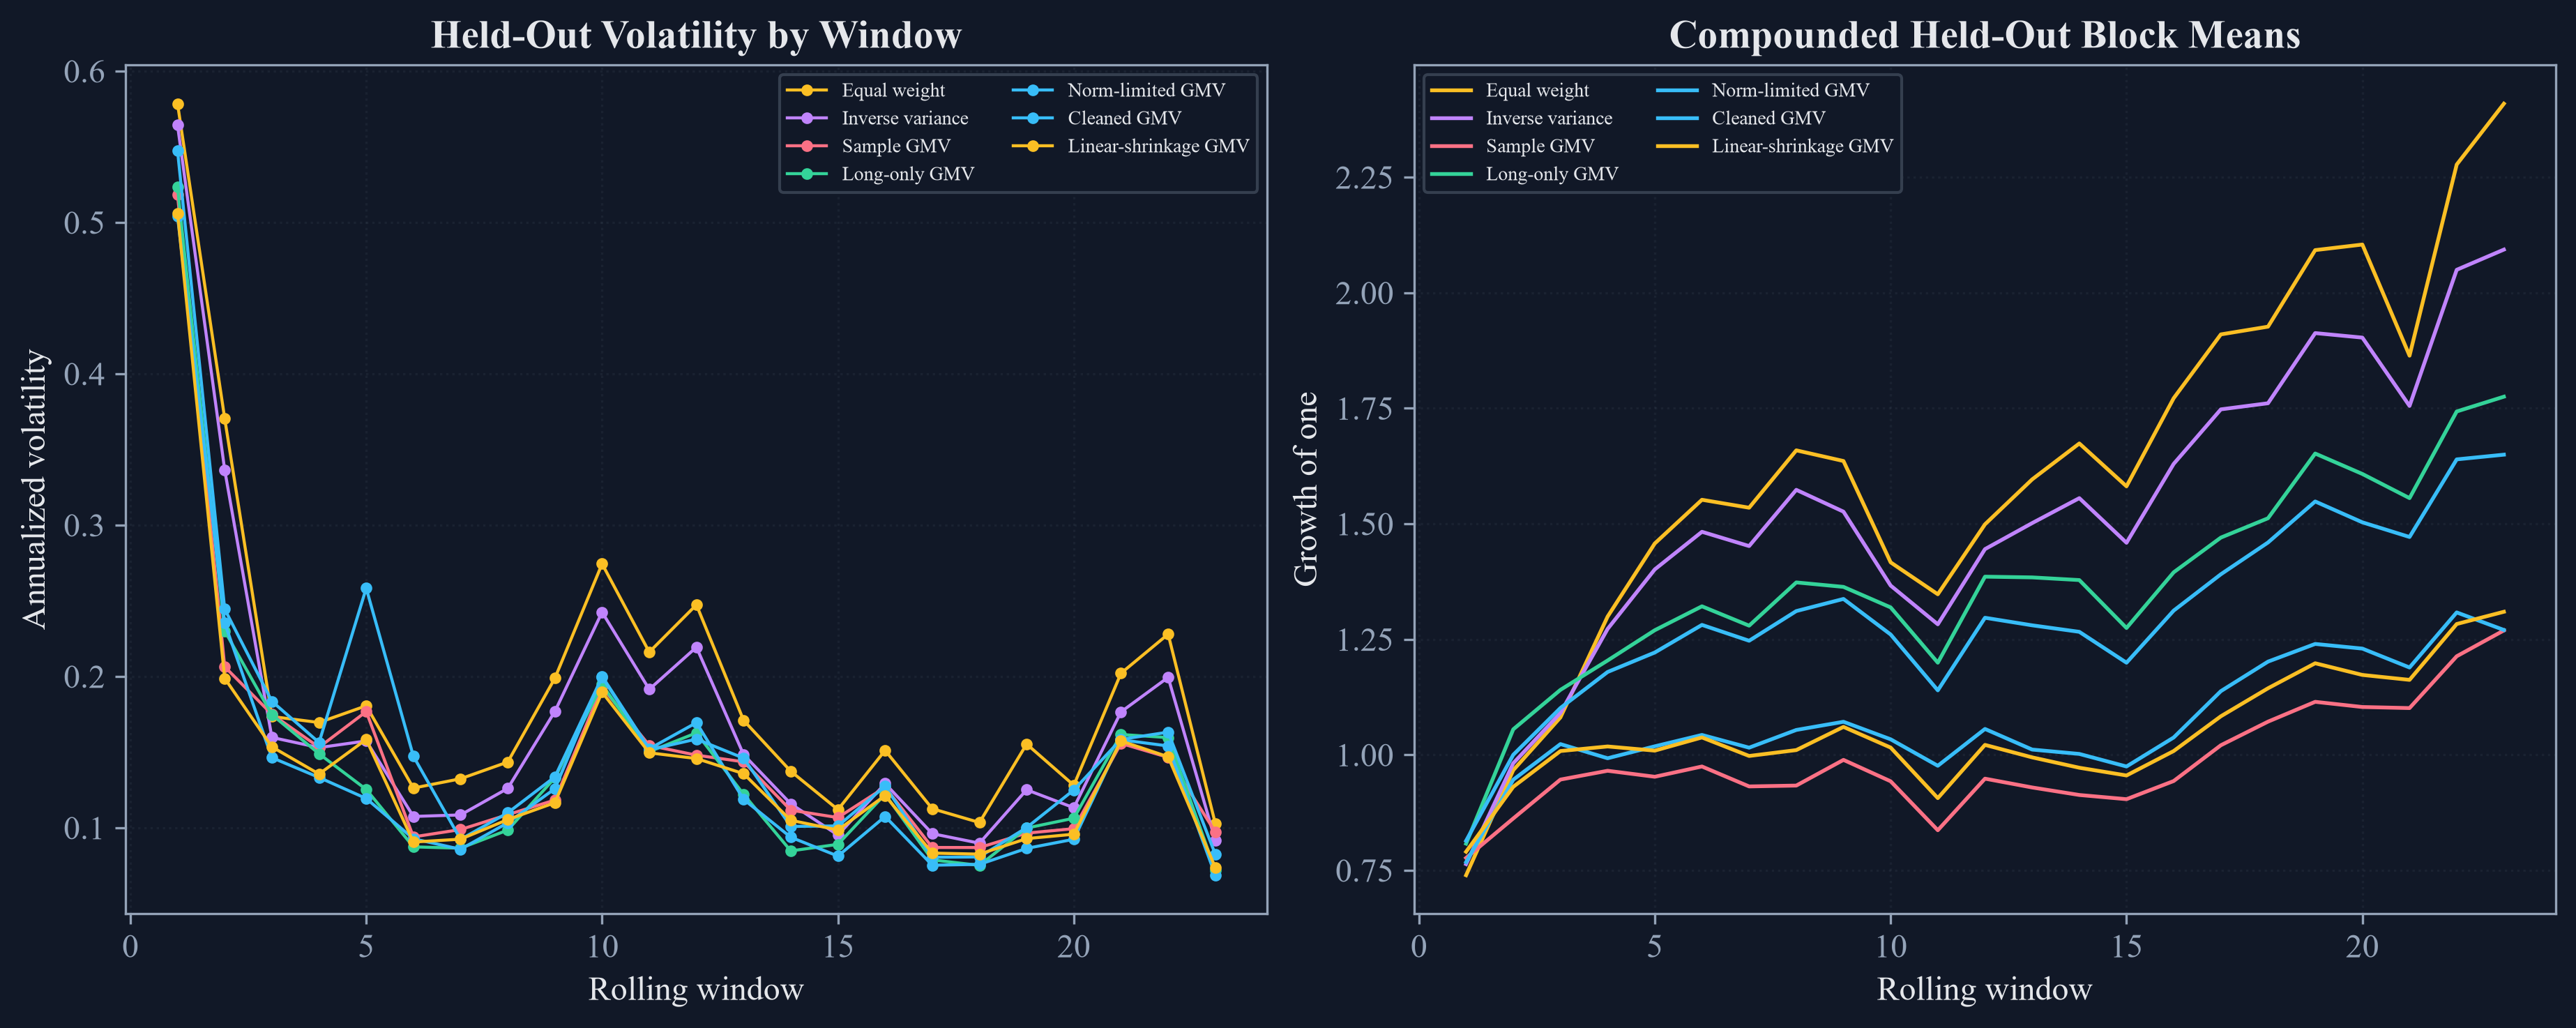

In [2]:
equal_risk = rolling_results.loc[rolling_results["Method"] == "Equal weight"].set_index("Fold")["Annualized test volatility"]
best_by_fold = rolling_results.loc[rolling_results.groupby("Fold")["Annualized test volatility"].idxmin(), ["Fold", "Method"]]
rolling_risk_rows = []
rolling_weight_rows = []
for method, group in rolling_results.groupby("Method", sort=False):
    risk = group.set_index("Fold")["Annualized test volatility"]
    rolling_risk_rows.append({
        "Method": method,
        "Mean annualized return": group["Annualized test return"].mean(),
        "Mean annualized volatility": risk.mean(),
        "Median annualized volatility": risk.median(),
        "Mean test Sharpe ratio": group["Test Sharpe ratio"].mean(),
        "Mean volatility ratio to equal weight": np.mean(risk / equal_risk),
        "Folds below equal-weight volatility": int((risk < equal_risk).sum()),
        "Lowest-volatility folds": int((best_by_fold["Method"] == method).sum()),
    })
    rolling_weight_rows.append({
        "Method": method,
        "Median gross exposure": group["Gross exposure"].median(),
        "Median largest absolute weight": group["Largest absolute weight"].median(),
        "Median effective holdings": group["Effective holdings"].median(),
        "Mean turnover": group["Turnover"].mean(),
        "Smallest observed weight": group["Smallest weight"].min(),
    })
rolling_risk_summary = pd.DataFrame(rolling_risk_rows)
rolling_weight_summary = pd.DataFrame(rolling_weight_rows)
fold_winners = best_by_fold["Method"].value_counts().rename_axis("Method").reset_index(name="Lowest-volatility folds")
save_table(rolling_risk_summary, "rolling_risk_summary", "Held-out risk and return across public rolling windows.", "tab:chapter20-rolling-risk")
save_table(rolling_weight_summary, "rolling_weight_summary", "Weight size, spread, and turnover across public rolling windows.", "tab:chapter20-rolling-weights")
save_table(fold_winners, "rolling_fold_winners", "Counts of the lowest-volatility method in each public test window.", "tab:chapter20-fold-winners")
display(rolling_risk_summary.round(6))
display(rolling_weight_summary.round(6))
display(fold_winners)

method_colors = {"Equal weight": palette["amber"], "Inverse variance": palette["violet"], "Sample GMV": palette["rose"], "Long-only GMV": palette["green"], "Norm-limited GMV": palette["cyan"], "Cleaned GMV": "#38BDF8", "Linear-shrinkage GMV": "#FBBF24"}
figure, axes = plt.subplots(1, 2, figsize=(12.2, 4.8), constrained_layout=True)
for method, group in rolling_results.groupby("Method", sort=False):
    axes[0].plot(group["Fold"], group["Annualized test volatility"], marker="o", markersize=3.0, linewidth=1.05, color=method_colors[method], label=method)
axes[0].set_title("Held-Out Volatility by Window")
axes[0].set_xlabel("Rolling window")
axes[0].set_ylabel("Annualized volatility")
axes[0].grid(alpha=0.26)
axes[0].legend(fontsize=6.7, ncol=2)
cumulative_paths = {}
for method in benchmark_definitions["Method"]:
    method_blocks = rolling_results.loc[rolling_results["Method"] == method].sort_values("Fold")
    block_growth = np.exp(method_blocks["Annualized test return"].to_numpy() * testing_days / 252.0)
    cumulative_paths[method] = np.cumprod(block_growth)
    axes[1].plot(np.arange(1, len(block_growth) + 1), cumulative_paths[method], linewidth=1.3, color=method_colors[method], label=method)
axes[1].set_title("Compounded Held-Out Block Means")
axes[1].set_xlabel("Rolling window")
axes[1].set_ylabel("Growth of one")
axes[1].grid(alpha=0.26)
axes[1].legend(fontsize=6.7, ncol=2)
save_figure(figure, "rolling_risk_return_paths")

## Diagnosing portfolio implementation

Weight concentration can be read as an effective number of equally weighted holdings:

$$
H(w)=\sum_{i=1}^{N}w_i^2,
\qquad
N_{\mathrm{eff}}(w)=\frac{1}{H(w)}.
$$

Here, $N$ is the number of assets, $H(w)$ is the squared-weight concentration, and $N_{\mathrm{eff}}(w)$ is the number of equal weights that would produce the same concentration. Negative weights also raise $H(w)$ because they enter as squares.

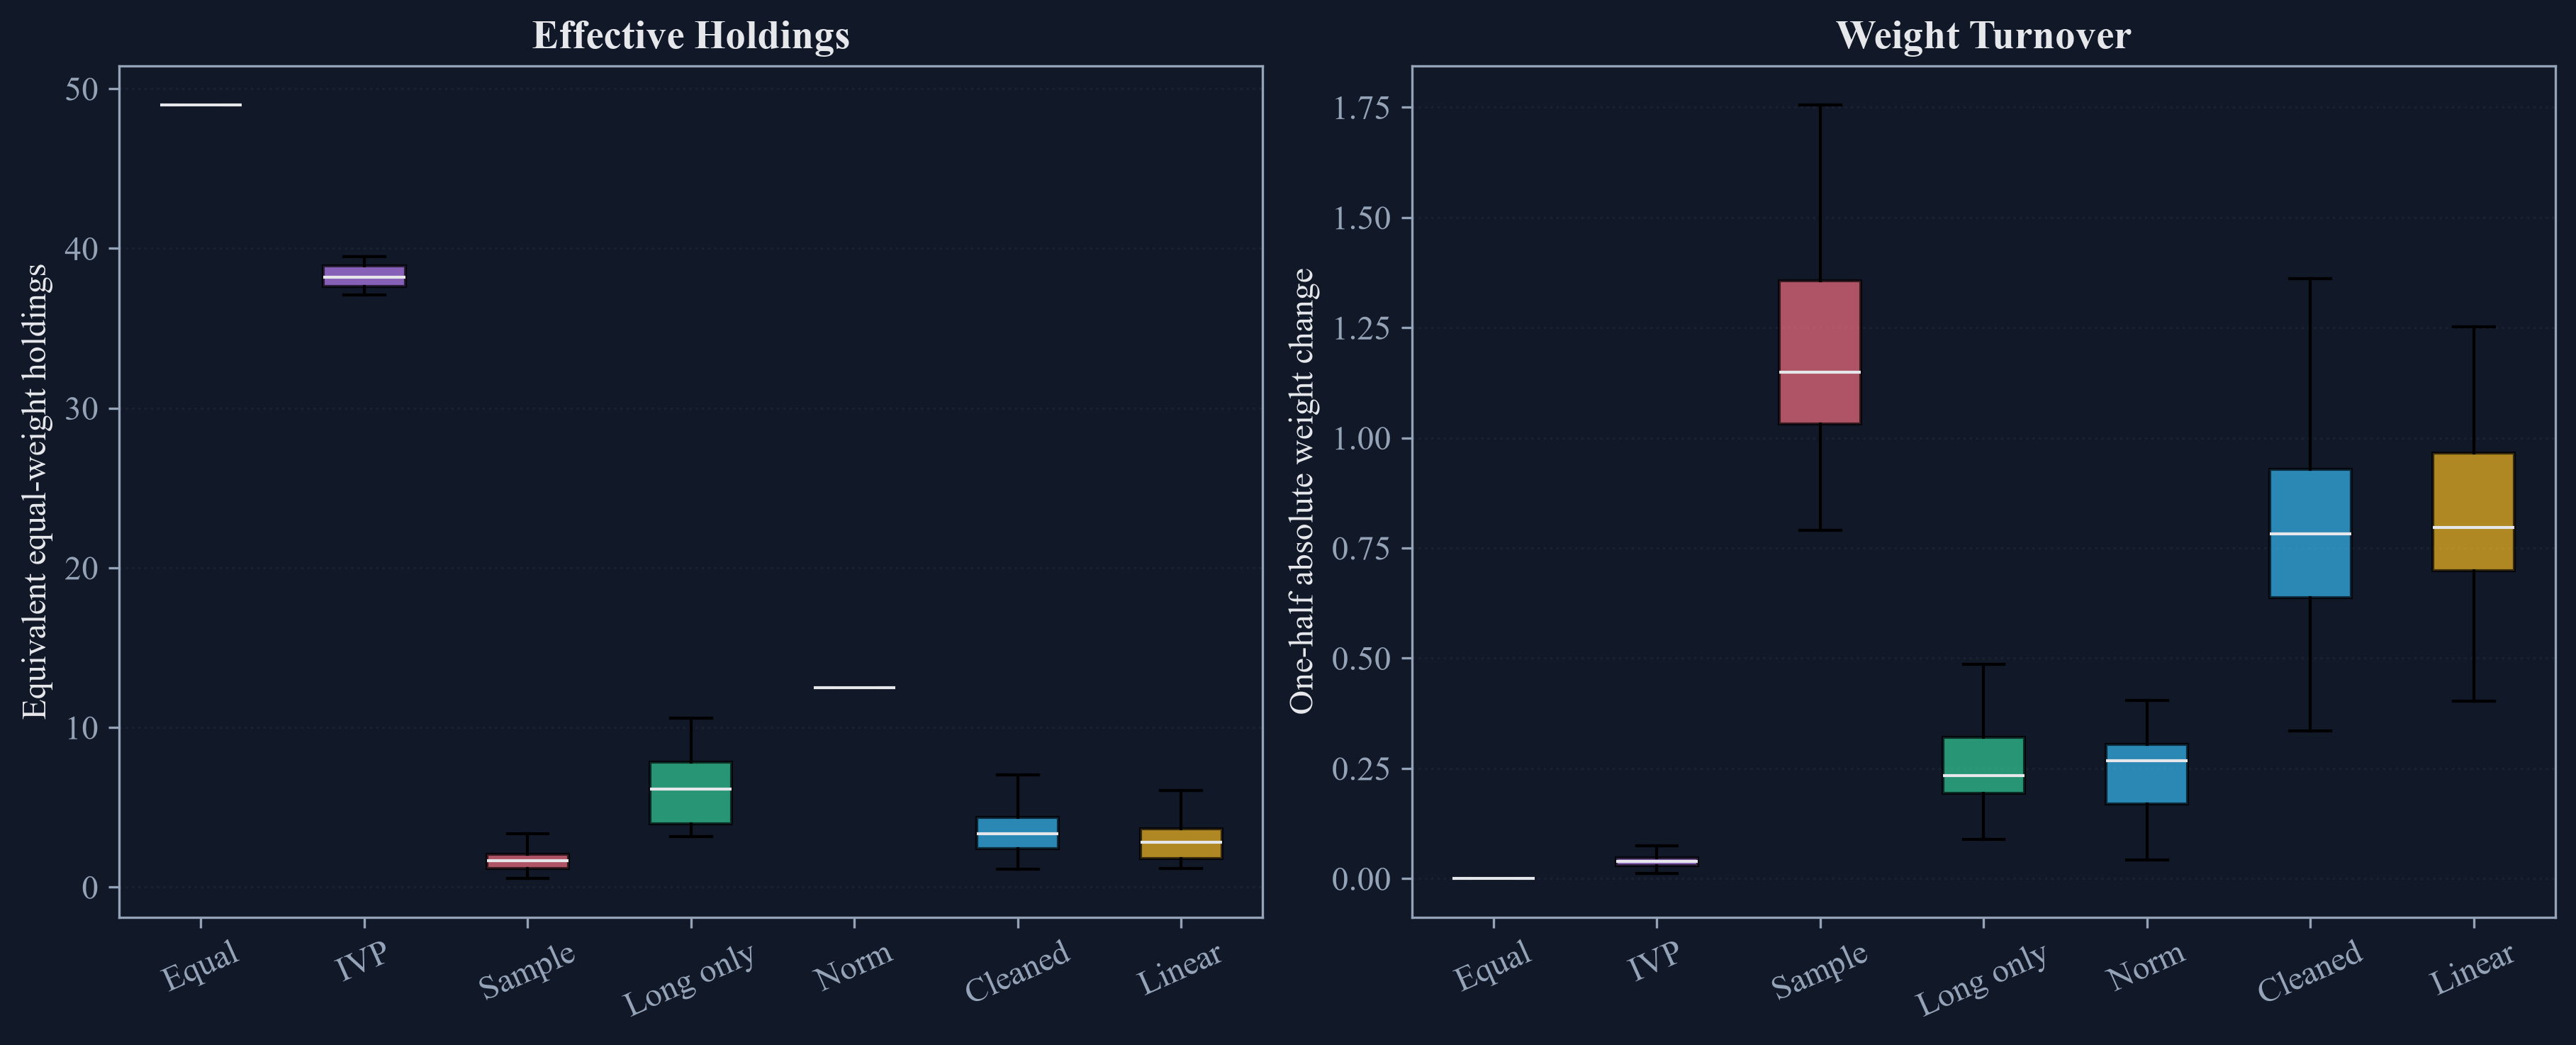

In [3]:
method_order = benchmark_definitions["Method"].tolist()
short_labels = ["Equal", "IVP", "Sample", "Long only", "Norm", "Cleaned", "Linear"]
figure, axes = plt.subplots(1, 2, figsize=(12.0, 4.8), constrained_layout=True)
effective_values = [rolling_results.loc[rolling_results["Method"] == method, "Effective holdings"].to_numpy() for method in method_order]
turnover_values = [rolling_results.loc[rolling_results["Method"] == method, "Turnover"].dropna().to_numpy() for method in method_order]
effective_plot = axes[0].boxplot(effective_values, tick_labels=short_labels, patch_artist=True, showfliers=False, medianprops={"color": palette["text"]})
turnover_plot = axes[1].boxplot(turnover_values, tick_labels=short_labels, patch_artist=True, showfliers=False, medianprops={"color": palette["text"]})
for patch, method in zip(effective_plot["boxes"], method_order):
    patch.set_facecolor(method_colors[method])
    patch.set_alpha(0.68)
for patch, method in zip(turnover_plot["boxes"], method_order):
    patch.set_facecolor(method_colors[method])
    patch.set_alpha(0.68)
axes[0].set_title("Effective Holdings")
axes[0].set_ylabel("Equivalent equal-weight holdings")
axes[1].set_title("Weight Turnover")
axes[1].set_ylabel("One-half absolute weight change")
for axis in axes:
    axis.tick_params(axis="x", rotation=24)
    axis.grid(axis="y", alpha=0.25)
save_figure(figure, "rolling_concentration_turnover")

## Stress-testing portfolio dimension

A stress ratio compares each method with equal weighting on the same held-out dates and asset set:

$$
S_{m}(T,N)
=\frac{\operatorname{sd}(R_{T,N}^{\mathrm{test}}w_{m,T,N})}{\operatorname{sd}(R_{T,N}^{\mathrm{test}}w_{\mathrm{EW},N})}.
$$

Here, $T$ is the number of training days, $N$ is the number of included industries, $R_{T,N}^{\mathrm{test}}$ is the common held-out return matrix, $w_{m,T,N}$ is the weight vector from method $m$, and $w_{\mathrm{EW},N}$ is the equal-weight vector. A ratio below one means lower volatility in that particular held-out block.

,Method,Mean volatility ratio,Smallest volatility ratio,Largest volatility ratio,Mean gross exposure,Mean effective holdings
0,Equal weight,1,1,1,1,30.333333
1,Sample GMV,0.909513,0.670807,1.303668,2.805681,2.991965
2,Long-only GMV,0.797515,0.686563,0.955187,1,7.419810
3,Norm-limited GMV,0.809078,0.679930,1,1.292521,12.333333
4,Cleaned GMV,0.826654,0.678095,0.965607,1.951937,4.687655


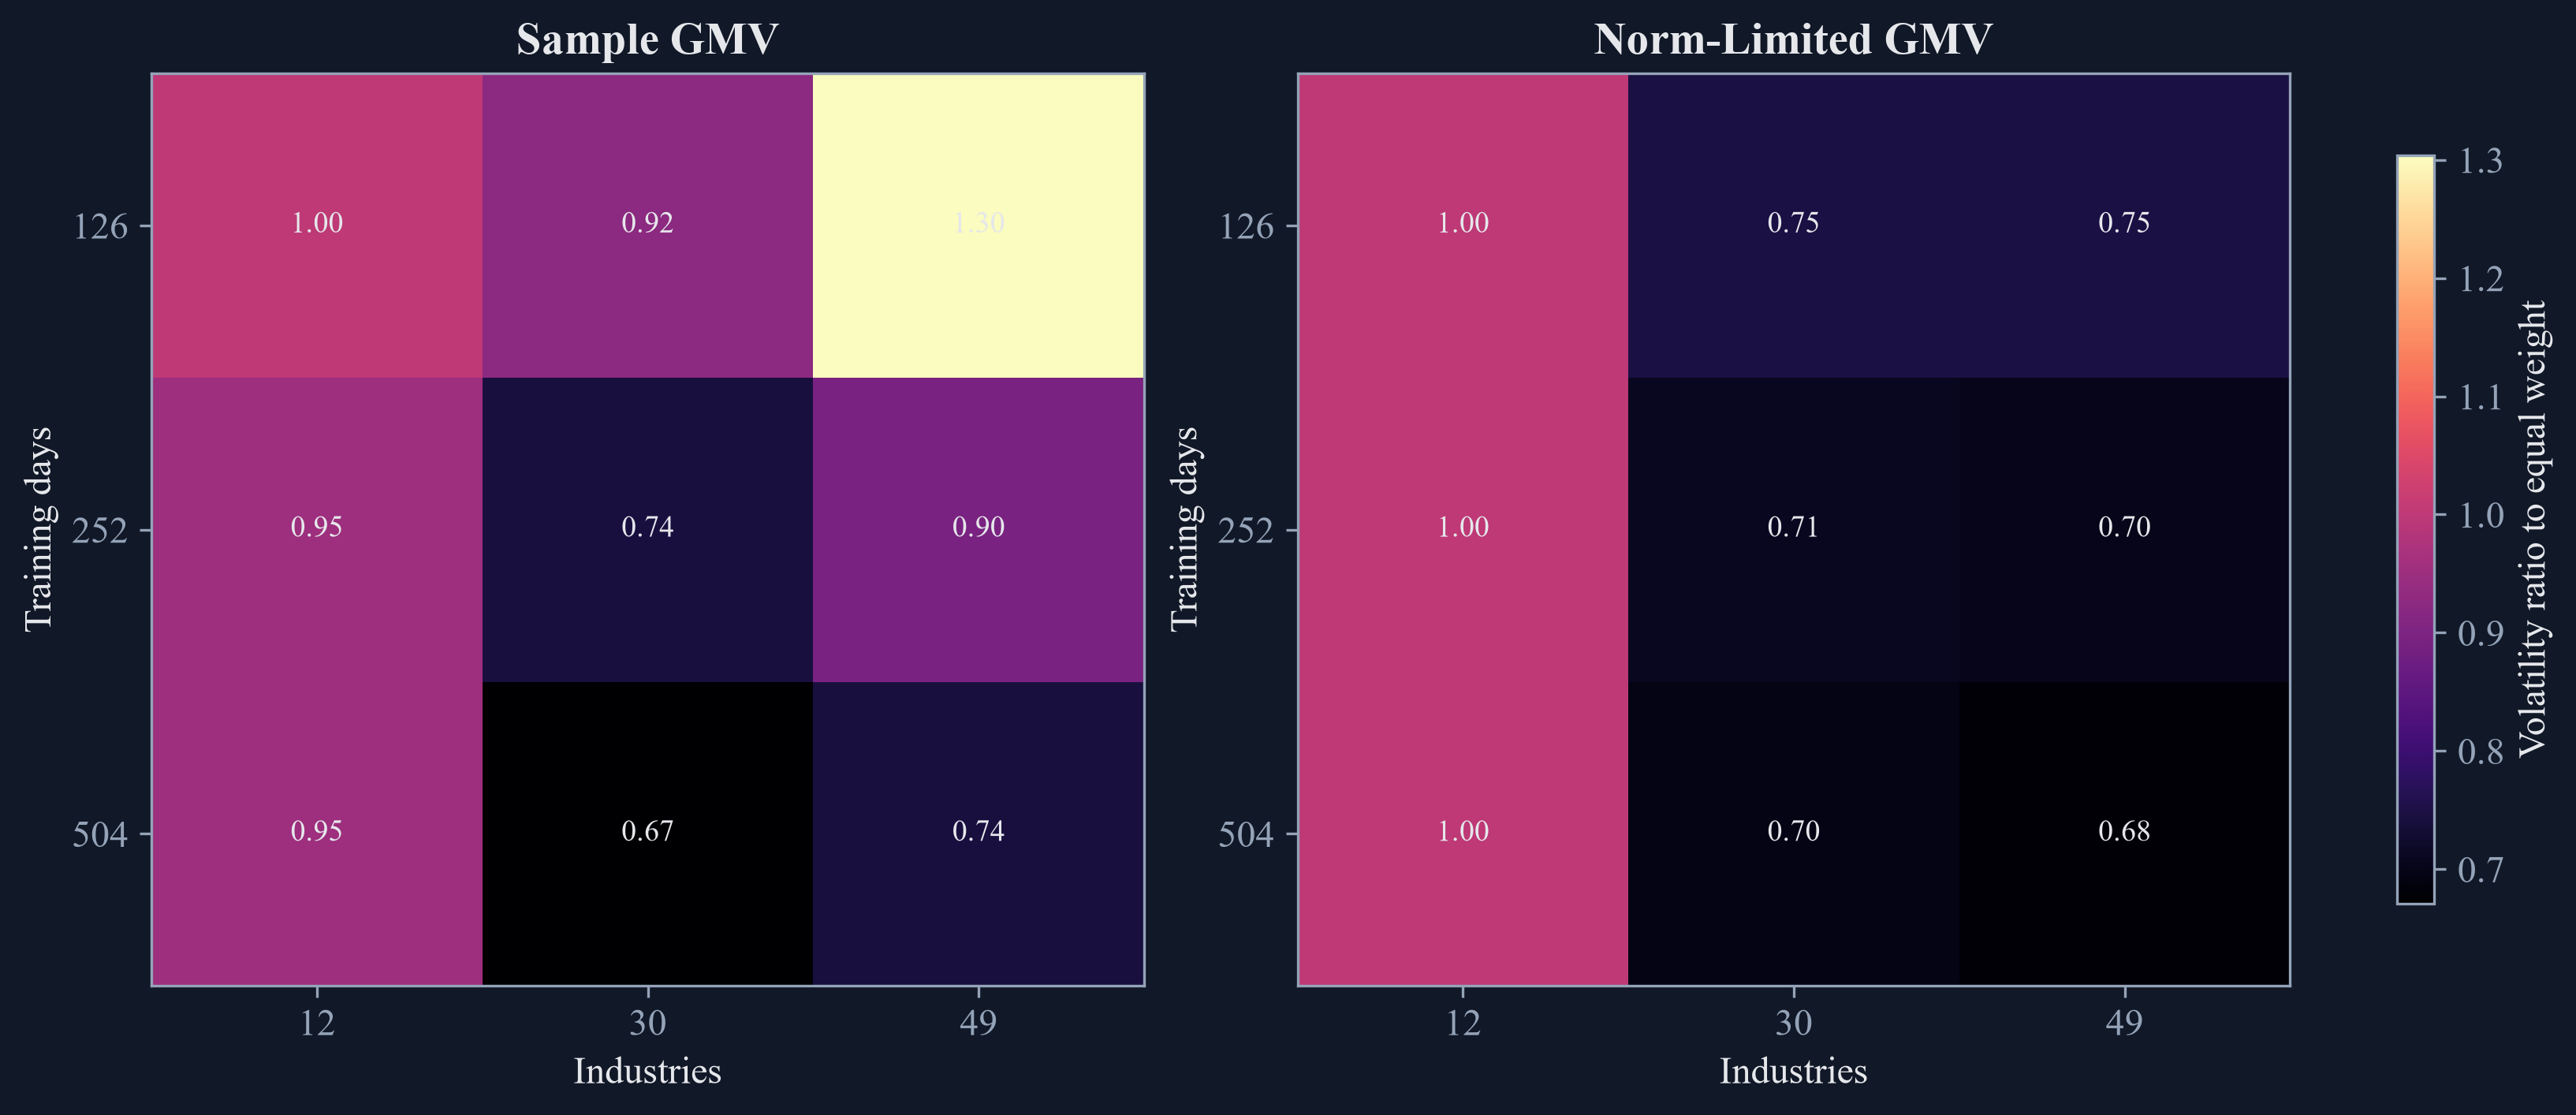

In [4]:
stress_training_days = [126, 252, 504]
stress_asset_counts = [12, 30, 49]
stress_testing_days = 126
stress_test = industry_returns.iloc[-stress_testing_days:]
stress_rows = []
for train_length in stress_training_days:
    stress_training = industry_returns.iloc[-stress_testing_days - train_length:-stress_testing_days]
    for count in stress_asset_counts:
        names = industry_returns.columns[:count]
        train_matrix = stress_training[names]
        test_matrix = stress_test[names]
        covariance = train_matrix.cov().to_numpy()
        cleaned = denoise_cov(covariance, train_length / count)
        equal_weights = np.repeat(1.0 / count, count)
        methods = {
            "Equal weight": equal_weights,
            "Sample GMV": global_minimum_variance(covariance),
            "Long-only GMV": long_only_minimum_variance(covariance),
            "Norm-limited GMV": norm_limited_minimum_variance(covariance, max(0.08, 1.0 / count)),
            "Cleaned GMV": global_minimum_variance(cleaned),
        }
        equal_volatility = np.std(test_matrix.to_numpy() @ equal_weights, ddof=1) * np.sqrt(252.0)
        for method, weights in methods.items():
            test_volatility = np.std(test_matrix.to_numpy() @ weights, ddof=1) * np.sqrt(252.0)
            stress_rows.append({
                "Training days": train_length,
                "Industries": count,
                "Method": method,
                "Covariance condition number": np.linalg.cond(covariance),
                "Annualized test volatility": test_volatility,
                "Volatility ratio to equal weight": test_volatility / equal_volatility,
                "Gross exposure": np.abs(weights).sum(),
                "Effective holdings": 1.0 / (weights @ weights),
            })
training_asset_stress = pd.DataFrame(stress_rows)
stress_summary = training_asset_stress.groupby("Method", sort=False).agg(**{
    "Mean volatility ratio": ("Volatility ratio to equal weight", "mean"),
    "Smallest volatility ratio": ("Volatility ratio to equal weight", "min"),
    "Largest volatility ratio": ("Volatility ratio to equal weight", "max"),
    "Mean gross exposure": ("Gross exposure", "mean"),
    "Mean effective holdings": ("Effective holdings", "mean"),
}).reset_index()
save_table(stress_summary, "training_asset_stress_summary", "Portfolio behavior across training lengths and asset counts.", "tab:chapter20-training-asset-stress")
save_table(training_asset_stress, "training_asset_stress_audit", "Complete training-length and asset-count stress results.", "tab:chapter20-training-asset-stress-audit")
display(stress_summary.round(6))

sample_heat = training_asset_stress.loc[training_asset_stress["Method"] == "Sample GMV"].pivot(index="Training days", columns="Industries", values="Volatility ratio to equal weight")
norm_heat = training_asset_stress.loc[training_asset_stress["Method"] == "Norm-limited GMV"].pivot(index="Training days", columns="Industries", values="Volatility ratio to equal weight")
figure, axes = plt.subplots(1, 2, figsize=(10.8, 4.6), constrained_layout=True)
for axis, matrix, title in [(axes[0], sample_heat, "Sample GMV"), (axes[1], norm_heat, "Norm-Limited GMV")]:
    image = axis.imshow(matrix.to_numpy(), cmap="magma", aspect="auto", vmin=min(sample_heat.min().min(), norm_heat.min().min()), vmax=max(sample_heat.max().max(), norm_heat.max().max()))
    axis.set_xticks(np.arange(len(matrix.columns)), matrix.columns)
    axis.set_yticks(np.arange(len(matrix.index)), matrix.index)
    axis.set_xlabel("Industries")
    axis.set_ylabel("Training days")
    axis.set_title(title)
    for row_index in range(matrix.shape[0]):
        for column_index in range(matrix.shape[1]):
            axis.text(column_index, row_index, f"{matrix.iloc[row_index, column_index]:.2f}", ha="center", va="center", color=palette["text"], fontsize=9)
figure.colorbar(image, ax=axes, shrink=0.82, label="Volatility ratio to equal weight")
save_figure(figure, "training_asset_stress_heatmaps")

## Diagnosing sources of portfolio error

A portfolio shock diagnostic reports weight movement and held-out risk relative to an unshocked choice:

$$
D_w(a)=\lVert w(a)-w(0)\rVert_1,
\qquad
D_\sigma(a)=\frac{\operatorname{sd}(R^{\mathrm{test}}w(a))}{\operatorname{sd}(R^{\mathrm{test}}w(0))}.
$$

Here, $a$ is the declared shock size, $w(0)$ is the portfolio before the shock, $w(a)$ is the shocked portfolio, $D_w(a)$ is absolute weight movement, $R^{\mathrm{test}}$ is the unchanged held-out return matrix, and $D_\sigma(a)$ is its volatility ratio.

,Shock type,Shock size,Weight absolute change,Held-out volatility ratio,Gross exposure
0,Covariance toward diagonal,0.10,1.987505,0.808531,2.795341
1,Covariance toward diagonal,0.25,2.828056,0.757706,2.082160
2,Covariance toward diagonal,0.50,3.438270,0.775688,1.488864
3,Expected return,0.10,1.317358,1.001457,6.798723
4,Expected return,0.25,3.419865,1.022656,7.005467
5,Expected return,0.50,7.307420,1.117617,7.993275


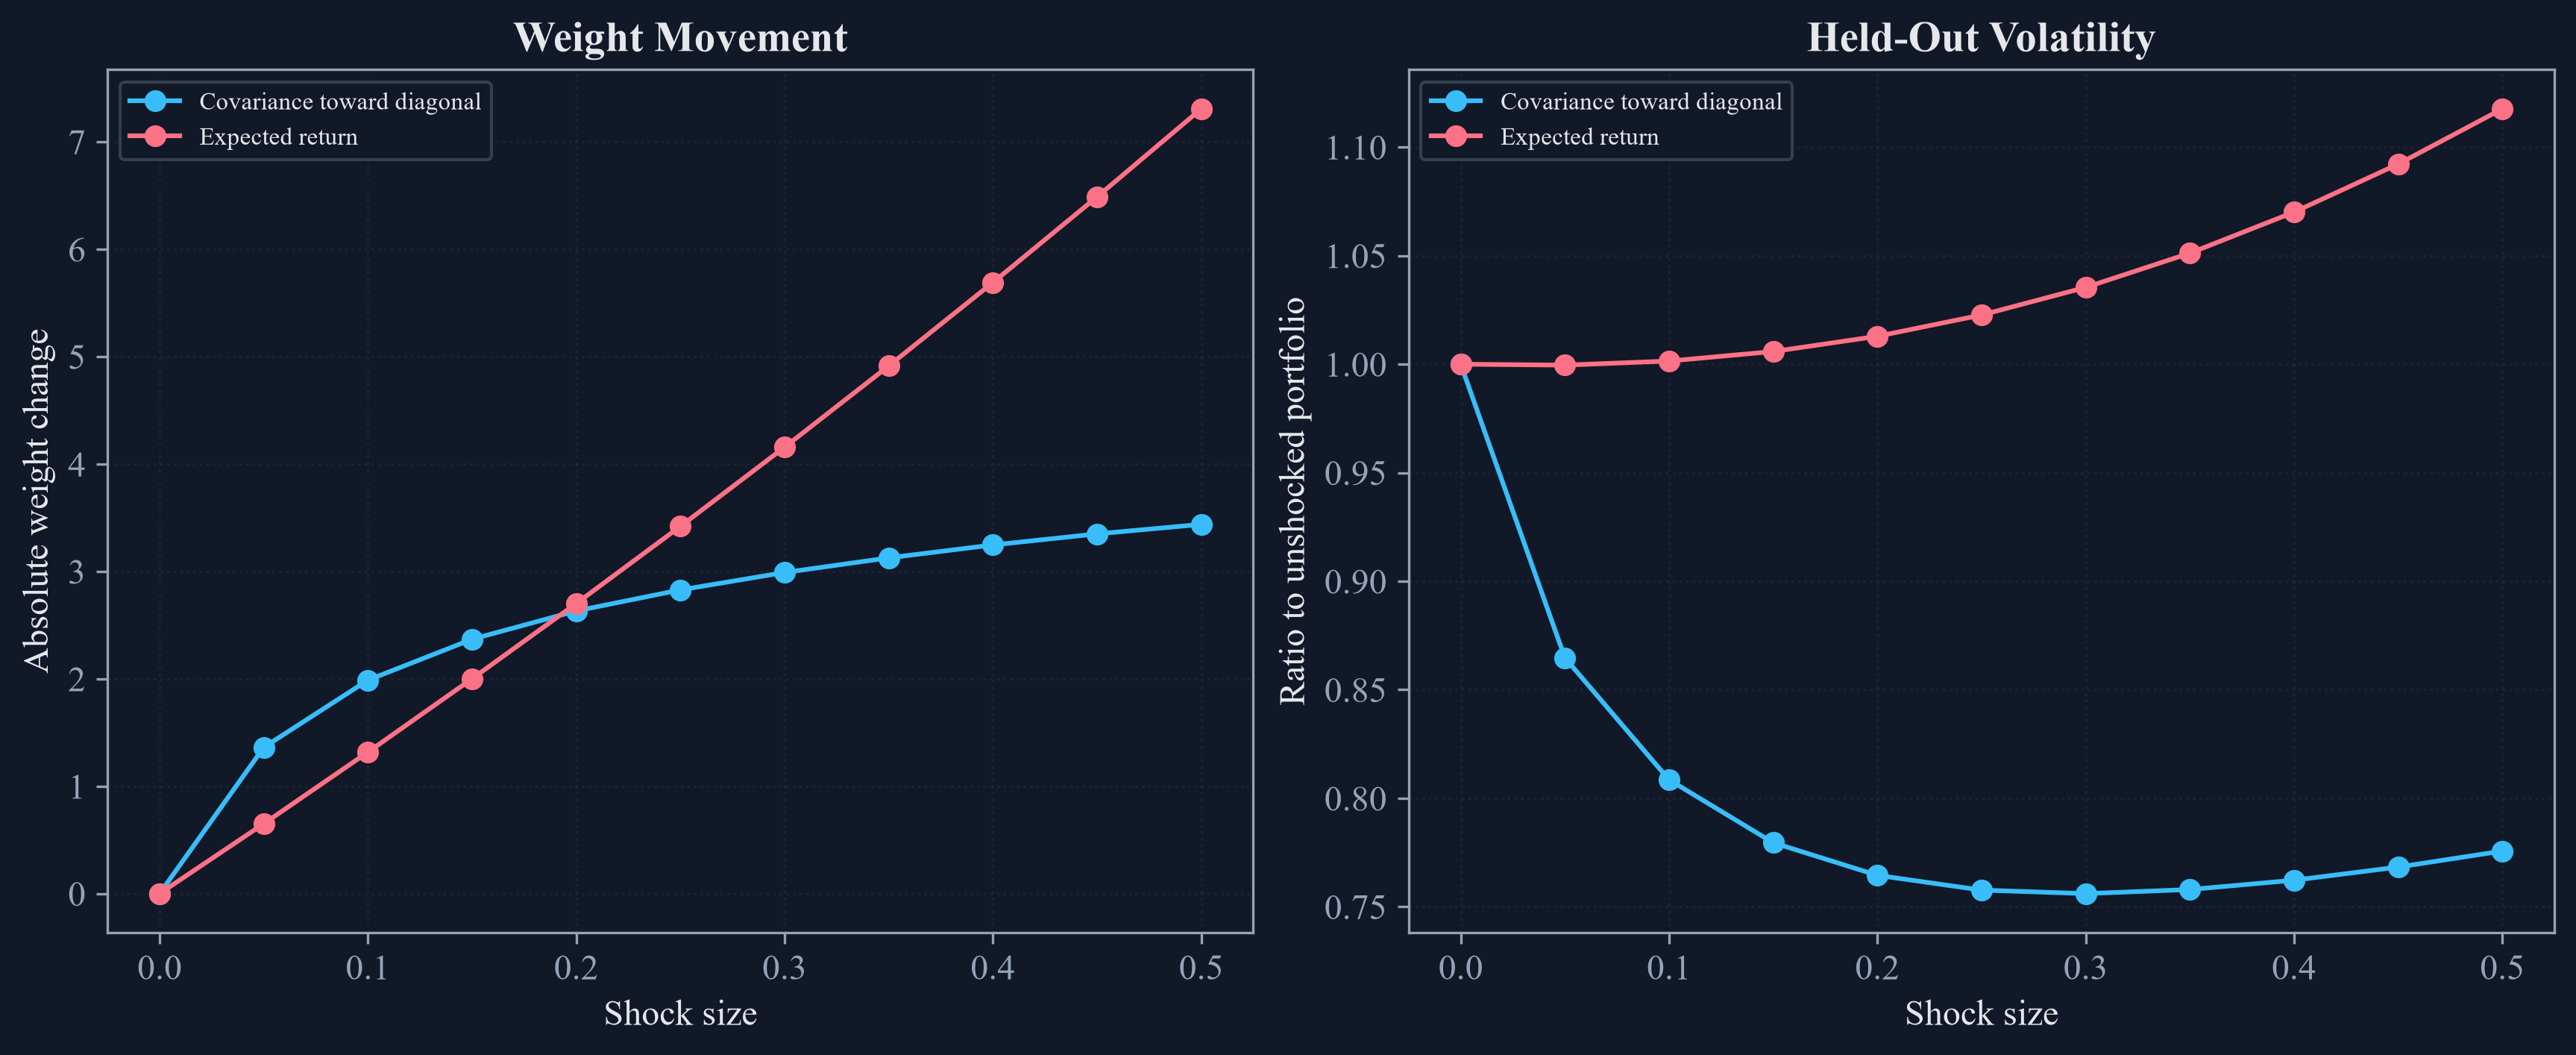

In [5]:
shock_training = industry_returns.iloc[-378:-126]
shock_testing = industry_returns.iloc[-126:]
shock_covariance = shock_training.cov().to_numpy()
shock_diagonal = np.diag(np.diag(shock_covariance))
covariance_shock_levels = np.linspace(0.0, 0.50, 11)
base_shock_weights = global_minimum_variance(shock_covariance)
base_shock_volatility = np.std(shock_testing.to_numpy() @ base_shock_weights, ddof=1)
covariance_shock_rows = []
for level in covariance_shock_levels:
    covariance = (1.0 - level) * shock_covariance + level * shock_diagonal
    weights = global_minimum_variance(covariance)
    covariance_shock_rows.append({
        "Shock type": "Covariance toward diagonal",
        "Shock size": level,
        "Weight absolute change": np.sum(np.abs(weights - base_shock_weights)),
        "Held-out volatility ratio": np.std(shock_testing.to_numpy() @ weights, ddof=1) / base_shock_volatility,
        "Gross exposure": np.abs(weights).sum(),
    })

mean_names = industry_returns.columns[:12]
mean_training = shock_training[mean_names]
mean_testing = shock_testing[mean_names]
mean_covariance = mean_training.cov().to_numpy()
estimated_mean = mean_training.mean().to_numpy()
base_mean_weights = mean_return_weighted(mean_covariance, estimated_mean)
base_mean_volatility = np.std(mean_testing.to_numpy() @ base_mean_weights, ddof=1)
mean_shock_direction = np.linspace(-1.0, 1.0, len(mean_names))
mean_shock_direction -= mean_shock_direction.mean()
mean_shock_direction /= np.linalg.norm(mean_shock_direction)
mean_shock_levels = np.linspace(0.0, 0.50, 11)
mean_shock_rows = []
for level in mean_shock_levels:
    shocked_mean = estimated_mean + level * np.linalg.norm(estimated_mean) * mean_shock_direction
    weights = mean_return_weighted(mean_covariance, shocked_mean)
    mean_shock_rows.append({
        "Shock type": "Expected return",
        "Shock size": level,
        "Weight absolute change": np.sum(np.abs(weights - base_mean_weights)),
        "Held-out volatility ratio": np.std(mean_testing.to_numpy() @ weights, ddof=1) / base_mean_volatility,
        "Gross exposure": np.abs(weights).sum(),
    })
shock_paths = pd.concat([pd.DataFrame(covariance_shock_rows), pd.DataFrame(mean_shock_rows)], ignore_index=True)
shock_summary = shock_paths.loc[shock_paths["Shock size"].isin([0.10, 0.25, 0.50])].reset_index(drop=True)
save_table(shock_summary, "portfolio_shock_summary", "Held-out effects of declared covariance and expected-return shocks.", "tab:chapter20-shock-summary")
save_table(shock_paths, "portfolio_shock_audit", "Complete covariance and expected-return shock paths.", "tab:chapter20-shock-audit")
display(shock_summary.round(6))

figure, axes = plt.subplots(1, 2, figsize=(11.4, 4.6), constrained_layout=True)
for shock_type, group in shock_paths.groupby("Shock type", sort=False):
    color = palette["cyan"] if shock_type.startswith("Covariance") else palette["rose"]
    axes[0].plot(group["Shock size"], group["Weight absolute change"], marker="o", color=color, label=shock_type)
    axes[1].plot(group["Shock size"], group["Held-out volatility ratio"], marker="o", color=color, label=shock_type)
axes[0].set_title("Weight Movement")
axes[0].set_xlabel("Shock size")
axes[0].set_ylabel("Absolute weight change")
axes[1].set_title("Held-Out Volatility")
axes[1].set_xlabel("Shock size")
axes[1].set_ylabel("Ratio to unshocked portfolio")
for axis in axes:
    axis.grid(alpha=0.28)
    axis.legend(fontsize=8)
save_figure(figure, "portfolio_shock_diagnostics")

## Tests

In [6]:
assert industry_returns.shape == (1760, 49)
assert fold_number > 15
assert len(rolling_results) == fold_number * 7
assert rolling_results.groupby('Method').size().eq(fold_number).all()
assert np.allclose(rolling_results['Weight sum'], 1.0)
assert rolling_results['Annualized test volatility'].gt(0.0).all()
assert rolling_results['Effective holdings'].gt(0.0).all()
assert rolling_results.loc[rolling_results['Method'] == 'Long-only GMV', 'Smallest weight'].min() >= -1e-08
assert rolling_results.loc[rolling_results['Method'] == 'Norm-limited GMV', 'Weight concentration'].max() <= norm_limit + 1e-07
assert best_by_fold.groupby('Fold').size().eq(1).all()
assert rolling_risk_summary['Lowest-volatility folds'].sum() == fold_number
assert len(training_asset_stress) == 45
assert training_asset_stress.groupby(['Training days', 'Industries']).size().eq(5).all()
assert np.allclose(training_asset_stress.loc[training_asset_stress['Method'] == 'Equal weight', 'Volatility ratio to equal weight'], 1.0)
assert len(shock_paths) == 22
assert shock_paths.loc[shock_paths['Shock size'] == 0.0, 'Weight absolute change'].max() < 1e-10
assert shock_paths.loc[shock_paths['Shock size'] == 0.0, 'Held-out volatility ratio'].sub(1.0).abs().max() < 1e-10
assert benchmark_definitions['Method'].nunique() == 7
assert (FIGURES / 'rolling_risk_return_paths.pdf').is_file()
assert (FIGURES / 'rolling_concentration_turnover.pdf').is_file()
assert (FIGURES / 'training_asset_stress_heatmaps.pdf').is_file()
assert (FIGURES / 'portfolio_shock_diagnostics.pdf').is_file()
assert (TABLES / 'rolling_risk_summary.tex').is_file()
assert (TABLES / 'portfolio_shock_summary.tex').is_file()
